## Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Loading data

In [2]:
amazon_df = pd.read_csv('amz_uk_price_prediction_dataset.csv')
amazon_df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


## Part 1: Understanding Product Categories

**Business Question**: What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?

1. **Frequency Tables**:
    - Generate a frequency table for the product `category`.
    - Which are the top 5 most listed product categories?

2. **Visualizations**:
    - Display the distribution of products across different categories using a bar chart. *If you face problems understanding the chart, do it for a subset of top categories.*
    - For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?

### 1 - Frequency tables

In [42]:
# 1a: create a frequency table for the 'category' column
cat_frequency = amazon_df['category'].value_counts()
cat_frequency

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Alexa Built-In Devices                       107
Motorbike Chassis                            107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64

In [43]:
#1b: Top 5 categories
top_5_categories = cat_frequency.head(5)
top_5_categories

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

Top 5 categories are Sports, Beauty, Handmade Clothing, Bath and Birthday Gifts

### 2 - Visualizations

#### 1. Bar charts

/var/folders/b4/svxttqvs5zg_rg_drrxn_vf00000gn/T/ipykernel_57432/2729273828.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cat_frequency.index, y=cat_frequency.values, palette="Set3")


<Axes: xlabel='category'>

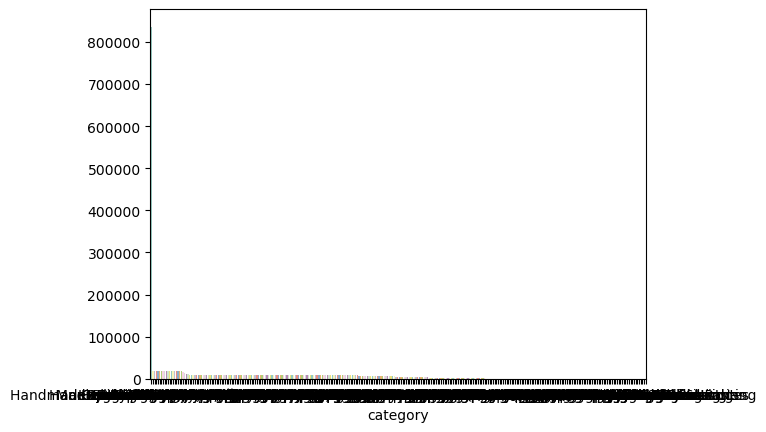

In [44]:
sns.barplot(x=cat_frequency.index, y=cat_frequency.values, palette="Set3")

Categories cannot be distinguish, let's try top 5

/var/folders/b4/svxttqvs5zg_rg_drrxn_vf00000gn/T/ipykernel_57432/318773506.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_5_categories.index, y=top_5_categories.values, palette="Set3")


<Axes: xlabel='category'>

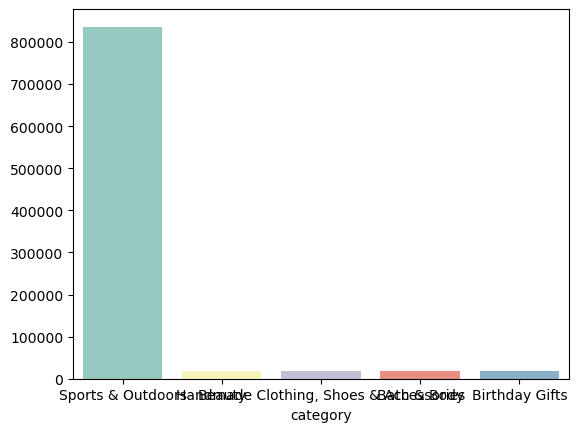

In [45]:
sns.barplot(x=top_5_categories.index, y=top_5_categories.values, palette="Set3")

/var/folders/b4/svxttqvs5zg_rg_drrxn_vf00000gn/T/ipykernel_57432/2665867386.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=top_5_categories.index, y=top_5_categories.values, palette="Set3")


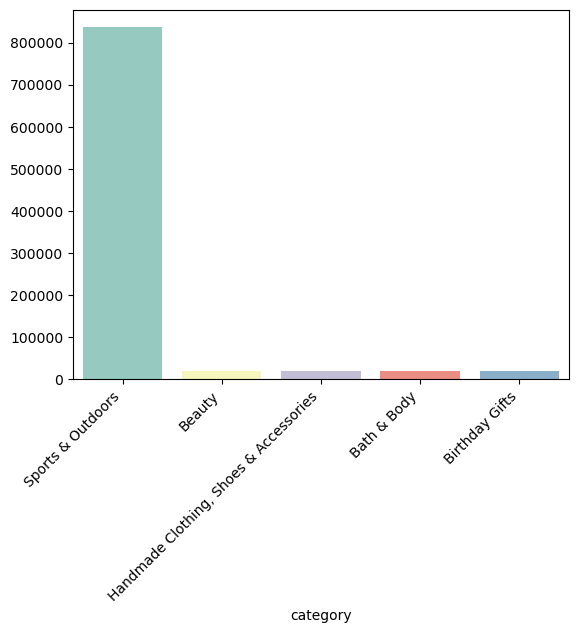

In [46]:
# The labels are overlapped, so we can rotate them for better visibility:

ax = sns.barplot(x=top_5_categories.index, y=top_5_categories.values, palette="Set3")
plt.xticks(rotation=45, ha='right')
plt.show()

#### 2. Pie chart

<Axes: ylabel='count'>

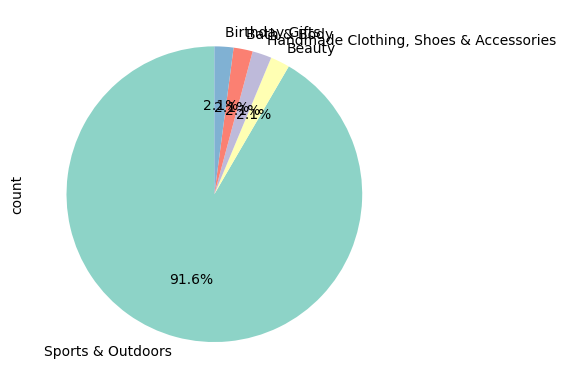

In [47]:
top_5_categories.plot.pie(autopct='%1.1f%%', startangle=90, colors=sns.color_palette("Set3"))


Categories and data are very overlapped, as a solution:

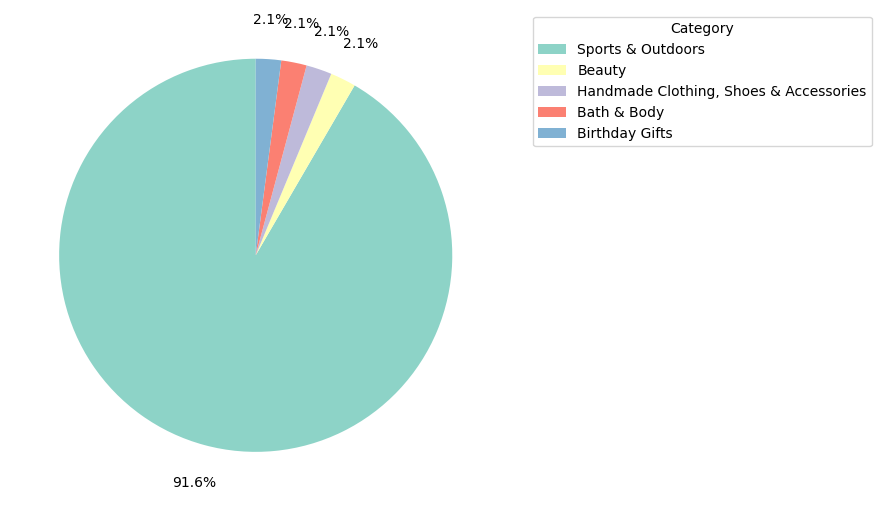

In [48]:
plt.figure(figsize=(9, 9))
top_5_categories.plot.pie(
    autopct='%1.1f%%',
    startangle=90,
    colors=sns.color_palette("Set3"),
    labels=None, #Takes out the labels from the pie chart
    pctdistance=1.2 #Takes the percentage labels out of the pie chart
)

plt.ylabel('')
plt.legend(top_5_categories.index, title='Category', bbox_to_anchor=(1.05, 1), loc='upper left') #Moves the legend outside of the pie chart
plt.tight_layout()
plt.show()


Summary: Sports & Outdoors is the predominant category, with ~92% of the products belonging to it.

## Part 2: Delving into Product Pricing

**Business Question**: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `price` of products.
    - What's the average price point of products listed? How does this compare with the most common price point (mode)?

2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, range, and interquartile range for product `price`.
    - How varied are the product prices? Are there any indicators of a significant spread in prices?

3. **Visualizations**:
    - Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. *If its hard to read these diagrams, think why this is, and explain how it could be solved.*.
    - Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing. 

### 1. Measures of centrality

In [52]:
mean_price = amazon_df['price'].mean()
median_price = amazon_df['price'].median()
mode_price = amazon_df['price'].mode()[0]

print(f'The mean is: {mean_price:.2f}')
print(f'The median is: {median_price:.2f}')
print(f'The mode is: {mode_price:.2f}')

The mean is: 89.24
The median is: 19.09
The mode is: 9.99


This means the typical product price is much lower than the average, because a relatively small number of expensive products are pulling the mean upward. The median is much closer to the mode, which suggests many products are sold at low price points, especially around 9.99 and similar values.

### 2. Measures of Dispersion

In [53]:
variance_price = amazon_df['price'].var()
std_dev_price = amazon_df['price'].std()
min_price = amazon_df['price'].min()
max_price = amazon_df['price'].max()
range_price = max_price - min_price
quantiles_price = amazon_df['price'].quantile([0.25, 0.5, 0.75])

print(f'The variance is: {variance_price:.2f}')
print(f'The standard deviation is: {std_dev_price:.2f}')
print(f'The range is: {range_price:.2f}')
print(f'The quantiles are: {quantiles_price.tolist()}')

The variance is: 119445.49
The standard deviation is: 345.61
The range is: 100000.00
The quantiles are: [9.99, 19.09, 45.99]


The product prices show high variability. The standard deviation is 345.61 and the range is 100,000, which indicates a very wide spread caused by at least one extreme price value. However, the interquartile range shows that the middle 50% of products are priced between 9.99 and 45.99, so most items are still concentrated at relatively low prices.

### 3 Visualizations
- Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. *If its hard to read these diagrams, think why this is, and explain how it could be solved.*.
 - Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing. 

<Axes: xlabel='price', ylabel='Count'>

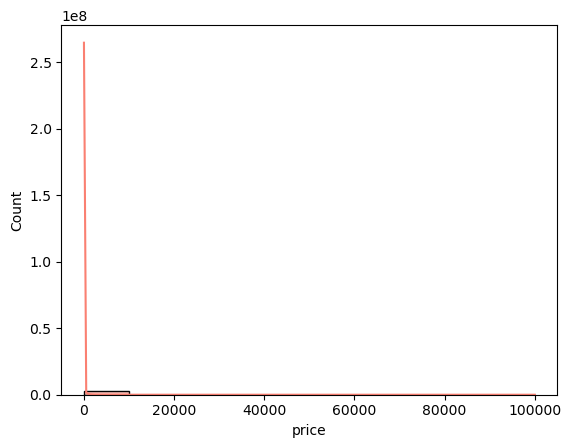

In [62]:
#1 Hisotgram of the 'price' column
sns.histplot(amazon_df['price'], kde=True, bins=10, color="salmon")

The histogram is difficult to read because the price distribution is highly right-skewed. A small number of very expensive products stretch the x-axis, which compresses most observations into the lowest price range. As a result, the main concentration of products is hard to see clearly

As an alternative, we can limit first the prices to 100 (as it is where most of the products fall) and then make an histogram out of it.

<Axes: xlabel='price', ylabel='Count'>

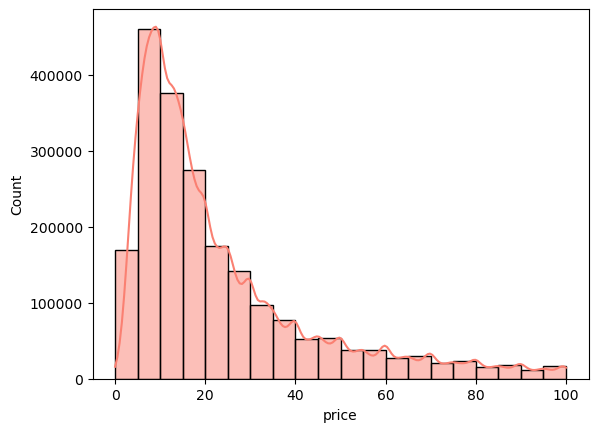

In [77]:
price_limited = amazon_df[amazon_df['price'] <= 100]

sns.histplot(price_limited['price'], kde=True, bins=20, color="salmon")


<Axes: ylabel='price'>

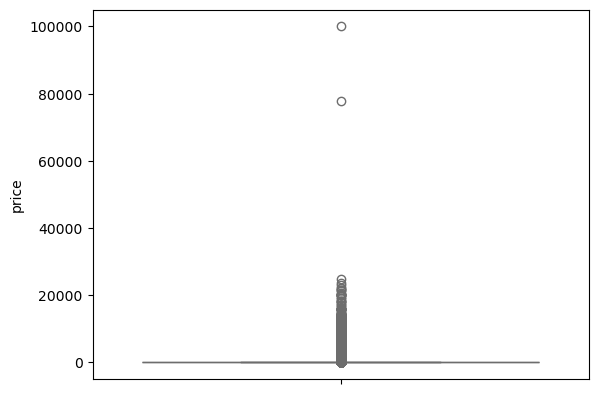

In [80]:
#2 Boxplot of the 'price' column
sns.boxplot(data=amazon_df['price'], color="salmon")

The box plot shows that most products are priced at relatively low levels, but there are several products with prices far above the rest. These appear as outliers above the upper whisker, including a few extremely high values. This indicates a strongly right-skewed distribution with a small number of expensive items stretching the scale.

## Part 3: Unpacking Product Ratings

**Business Question**: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `rating` of products.
    - How do customers generally rate products? Is there a common trend?

2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, and interquartile range for product `rating`.
    - Are the ratings consistent, or is there a wide variation in customer feedback?

3. **Shape of the Distribution**:
    - Calculate the skewness and kurtosis for the `rating` column. 
    - Are the ratings normally distributed, or do they lean towards higher or lower values?

4. **Visualizations**:
    - Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?


### 1.Measures of Centrality:
- Calculate the mean, median, and mode for the `rating` of products.
- How do customers generally rate products? Is there a common trend?

In [91]:
rating_mean = amazon_df['stars'].mean()
rating_median = amazon_df['stars'].median()
rating_mode = amazon_df['stars'].mode()[0]

print(f'The mean is: {rating_mean:.2f}')
print(f'The median is: {rating_median:.2f}')
print(f'The mode is: {rating_mode:.2f}')

The mean is: 2.15
The median is: 0.00
The mode is: 0.00


The ratings are very low. Let's check how they are distributed.

In [92]:
amazon_df['stars'].value_counts().head(10)
amazon_df['stars'].value_counts(normalize=True).head(10)

stars
0.0    0.501561
4.5    0.062029
4.6    0.056062
4.4    0.055722
5.0    0.052582
4.3    0.046064
4.7    0.038699
4.2    0.035550
4.0    0.027045
4.1    0.026647
Name: proportion, dtype: float64

The stars distribution is unusual because 50.16% of products have a rating of 0.0, likely representing missing or unrated items. Among the products with actual ratings, the most common values are around 4.4 to 4.6, which suggests that rated products are generally well reviewed. Because of the large number of zeros, the median and mode are not representative of the rated products, and the mean is pulled down by the zero values.

### 2.Measures of Dispersion
- Determine the variance, standard deviation, and interquartile range for product `rating`.
- Are the ratings consistent, or is there a wide variation in customer feedback?

In [95]:
variance_rating= amazon_df['stars'].var()
std_dev_rating= amazon_df['stars'].std()
min_rating = amazon_df['stars'].min()
max_rating = amazon_df['stars'].max()
range_rating = max_rating - min_rating
quantiles_rating = amazon_df['stars'].quantile([0.25, 0.5, 0.75])

print(f'The variance is: {variance_rating:.2f}')
print(f'The standard deviation is: {std_dev_rating:.2f}')
print(f'The range is: {range_rating:.2f}')
print(f'The quantiles are: {quantiles_rating.tolist()}')

The variance is: 4.82
The standard deviation is: 2.19
The range is: 5.00
The quantiles are: [0.0, 0.0, 4.4]


The ratings show considerable variation. The median and lower quartile are both 0.0, while the upper quartile is 4.4, which indicates that many products have no recorded rating or a placeholder value of 0.0, while others have high customer ratings. This suggests the ratings are not consistent across the dataset and the distribution is strongly uneven.


### 3. Shape of the Distribution
- Calculate the skewness and kurtosis for the `rating` column. 
- Are the ratings normally distributed, or do they lean towards higher or lower values?

In [96]:
rating_skewness = amazon_df['stars'].skew()
rating_kurtosis = amazon_df['stars'].kurtosis()

print(f'Skewness: {rating_skewness:.2f}')
print(f'Kurtosis: {rating_kurtosis:.2f}')


Skewness: 0.08
Kurtosis: -1.93


Skewness measures the asymmetry of the distribution, while kurtosis measures how peaked or flat it is compared with a normal distribution. In this dataset, skewness is close to 0, so the ratings are roughly symmetric, but kurtosis is negative, which means the distribution is flatter than normal. This suggests the ratings are not normally distributed and are influenced by many 0.0 values

### 4. Visualizations
- Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?

<Axes: xlabel='stars', ylabel='Count'>

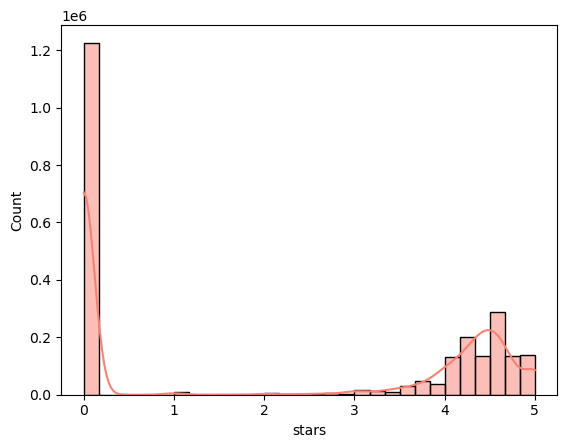

In [102]:
sns.histplot(amazon_df['stars'], kde=True, bins=30, color="salmon")

As can be seen, 0 rating is the most common one.